## 1. Imports & Setup

In [1]:
import numpy as np
import re
import random
import pickle
import matplotlib.pyplot as plt
from collections import Counter
from datasets import load_dataset
from tqdm import tqdm

# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print('All imports successful.')

C:\Users\OPT\AppData\Roaming\Python\Python310\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports successful.


## 2. Dataset Loading

In [2]:
# Load CoNLL-2003 from HuggingFace
dataset = load_dataset('lhoestq/conll2003')

# Extract all tokens from train, validation and test splits
all_sentences = []
for split in ['train', 'validation', 'test']:
    for example in dataset[split]:
        all_sentences.append(example['tokens'])

print(f'Total sentences: {len(all_sentences)}')
print(f'Example sentence: {all_sentences[0]}')

Total sentences: 20744
Example sentence: ['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.']


## 3. Preprocessing

In [3]:
def preprocess_token(token: str) -> str:
    """
    Lowercase and remove non-alphanumeric characters except hyphens.
    Returns None for tokens that are purely punctuation/numbers.
    """
    token = token.lower()
    token = re.sub(r"[^a-z0-9\-]", "", token)
    return token if len(token) > 0 else None


def preprocess_corpus(sentences):
    """Clean and tokenize every sentence."""
    cleaned = []
    for sent in sentences:
        tokens = [preprocess_token(t) for t in sent]
        tokens = [t for t in tokens if t is not None]
        if tokens:
            cleaned.append(tokens)
    return cleaned


corpus = preprocess_corpus(all_sentences)

print(f'Sentences after preprocessing : {len(corpus)}')
print(f'Example cleaned sentence      : {corpus[0]}')

Sentences after preprocessing : 20718
Example cleaned sentence      : ['eu', 'rejects', 'german', 'call', 'to', 'boycott', 'british', 'lamb']


## 4. Vocabulary Building

In [4]:
MIN_FREQ = 2   # discard very rare tokens

# Count token frequencies across the full corpus
flat_tokens = [token for sent in corpus for token in sent]
freq = Counter(flat_tokens)

# Filter by minimum frequency
vocab_tokens = [w for w, c in freq.items() if c >= MIN_FREQ]
vocab_tokens.sort()   # deterministic ordering

word2idx = {w: i for i, w in enumerate(vocab_tokens)}
idx2word = {i: w for w, i in word2idx.items()}
VOCAB_SIZE = len(vocab_tokens)

print(f'Vocabulary size : {VOCAB_SIZE}')
print(f'Total tokens    : {len(flat_tokens)}')

Vocabulary size : 13836
Total tokens    : 265446


## 5. Training Pair Generation (Skip-Gram)

In [5]:
WINDOW_SIZE = 2   # context window on each side

def generate_skipgram_pairs(corpus, word2idx, window_size):
    """
    For every target word, pair it with each word in its context window.
    Returns a list of (target_idx, context_idx) tuples.
    """
    pairs = []
    for sent in corpus:
        # Keep only in-vocabulary tokens
        indices = [word2idx[t] for t in sent if t in word2idx]
        for i, target in enumerate(indices):
            left  = max(0, i - window_size)
            right = min(len(indices), i + window_size + 1)
            for j in range(left, right):
                if j != i:
                    pairs.append((target, indices[j]))
    return pairs


pairs = generate_skipgram_pairs(corpus, word2idx, WINDOW_SIZE)
print(f'Total training pairs : {len(pairs)}')
print(f'Example pair (target, context): {pairs[0]} => ({idx2word[pairs[0][0]]}, {idx2word[pairs[0][1]]})')

Total training pairs : 891058
Example pair (target, context): (5122, 10556) => (eu, rejects)


## 6. Negative Sampling Table

In [6]:
def build_negative_sampling_table(word2idx, freq, table_size=1_000_000, power=0.75):
    """
    Build a large lookup table for fast negative sampling.
    Words are drawn proportional to freq(w)^power.
    """
    vocab = list(word2idx.keys())
    # Compute adjusted frequencies
    adjusted = np.array([freq.get(w, 0) ** power for w in vocab], dtype=np.float64)
    adjusted /= adjusted.sum()

    # Fill the table
    table = np.zeros(table_size, dtype=np.int32)
    idx = 0
    cumulative = 0.0
    for i, w in enumerate(vocab):
        cumulative += adjusted[i]
        while idx < table_size and idx / table_size < cumulative:
            table[idx] = word2idx[w]
            idx += 1
    return table


neg_table = build_negative_sampling_table(word2idx, freq)
print(f'Negative sampling table built. Size: {len(neg_table)}')


def get_negative_samples(target_idx, context_idx, neg_table, k):
    """
    Draw k negative samples, ensuring they differ from both target and context.
    """
    negs = []
    while len(negs) < k:
        neg = neg_table[random.randint(0, len(neg_table) - 1)]
        if neg != target_idx and neg != context_idx:
            negs.append(neg)
    return negs

Negative sampling table built. Size: 1000000


## 7. Word2Vec Model — Scratch Implementation

### Architecture
- **W_in**  : `(VOCAB_SIZE × EMBED_DIM)` — target (center) embeddings
- **W_out** : `(VOCAB_SIZE × EMBED_DIM)` — context embeddings

### Forward Pass
$$\text{score} = \mathbf{v}_{\text{target}} \cdot \mathbf{u}_{\text{context}}$$
$$\sigma(x) = \frac{1}{1 + e^{-x}}$$

### Loss (Negative Sampling objective)
$$\mathcal{L} = -\log \sigma(\mathbf{v}_t \cdot \mathbf{u}_c) - \sum_{k=1}^{K} \log \sigma(-\mathbf{v}_t \cdot \mathbf{u}_{n_k})$$

### Gradients (manual back-prop)

Let $\mathbf{v} = W\_in[t]$, $\mathbf{u}_c = W\_out[c]$, $\mathbf{u}_{n_k} = W\_out[n_k]$.

$$\frac{\partial \mathcal{L}}{\partial \mathbf{v}} = (\sigma(\mathbf{v}\cdot\mathbf{u}_c) - 1)\,\mathbf{u}_c + \sum_{k}(\sigma(\mathbf{v}\cdot\mathbf{u}_{n_k}))\,\mathbf{u}_{n_k}$$

$$\frac{\partial \mathcal{L}}{\partial \mathbf{u}_c} = (\sigma(\mathbf{v}\cdot\mathbf{u}_c) - 1)\,\mathbf{v}$$

$$\frac{\partial \mathcal{L}}{\partial \mathbf{u}_{n_k}} = \sigma(\mathbf{v}\cdot\mathbf{u}_{n_k})\,\mathbf{v}$$

In [7]:
class Word2VecSGNS:
    """
    Skip-Gram with Negative Sampling, fully implemented from scratch.
    No PyTorch nn.Module, no autograd.
    """

    def __init__(self, vocab_size: int, embed_dim: int, learning_rate: float = 0.025):
        self.vocab_size   = vocab_size
        self.embed_dim    = embed_dim
        self.lr           = learning_rate

        # Xavier-style uniform initialisation
        scale = np.sqrt(1.0 / embed_dim)
        self.W_in  = np.random.uniform(-scale, scale, (vocab_size, embed_dim)).astype(np.float32)
        self.W_out = np.zeros((vocab_size, embed_dim), dtype=np.float32)

    # ------------------------------------------------------------------
    # Utilities
    # ------------------------------------------------------------------
    @staticmethod
    def sigmoid(x):
        """Numerically stable sigmoid."""
        return np.where(x >= 0,
                        1.0 / (1.0 + np.exp(-x)),
                        np.exp(x) / (1.0 + np.exp(x)))

    # ------------------------------------------------------------------
    # Forward + Backward for a single (target, context, negatives) tuple
    # ------------------------------------------------------------------
    def forward_backward(self, target_idx: int, context_idx: int, neg_indices: list):
        """
        Perform one forward pass, compute SGNS loss, compute gradients
        manually, and apply SGD update.

        Returns the scalar loss for this sample.
        """
        v  = self.W_in[target_idx]          # (D,)
        u_c = self.W_out[context_idx]       # (D,)
        U_n = self.W_out[neg_indices]       # (K, D)

        # ---- Forward ------------------------------------------------
        # Positive score
        score_pos = np.dot(v, u_c)          # scalar
        sig_pos   = self.sigmoid(score_pos) # σ(v·u_c)

        # Negative scores
        scores_neg = U_n @ v                # (K,)
        sig_neg    = self.sigmoid(scores_neg) # (K,)  σ(v·u_nk)

        # ---- Loss ---------------------------------------------------
        eps  = 1e-10
        loss = -np.log(sig_pos + eps) - np.sum(np.log(1.0 - sig_neg + eps))

        # ---- Gradients (manual back-prop) ---------------------------
        # Gradient w.r.t. v  (target embedding)
        grad_v = (sig_pos - 1.0) * u_c + np.sum(sig_neg[:, np.newaxis] * U_n, axis=0)

        # Gradient w.r.t. u_c  (positive context embedding)
        grad_u_c = (sig_pos - 1.0) * v

        # Gradient w.r.t. each u_nk  (negative context embeddings)
        grad_U_n = sig_neg[:, np.newaxis] * v[np.newaxis, :]  # (K, D)

        # ---- SGD Update ---------------------------------------------
        self.W_in[target_idx]    -= self.lr * grad_v
        self.W_out[context_idx]  -= self.lr * grad_u_c
        for i, neg_idx in enumerate(neg_indices):
            self.W_out[neg_idx]  -= self.lr * grad_U_n[i]

        return float(loss)

    # ------------------------------------------------------------------
    # Embedding retrieval
    # ------------------------------------------------------------------
    def get_embedding(self, word_idx: int) -> np.ndarray:
        """Return the trained embedding for a single word index."""
        return self.W_in[word_idx]

    def get_all_embeddings(self) -> np.ndarray:
        """Return the full target embedding matrix (VOCAB_SIZE × EMBED_DIM)."""
        return self.W_in.copy()


print('Word2VecSGNS class defined.')

Word2VecSGNS class defined.


## 8. Training Loop

In [8]:
# ── Hyperparameters ──────────────────────────────────────────────────
EMBED_DIM     = 100     # embedding dimensionality
NUM_EPOCHS    = 5       # number of passes over the training data
K_NEGATIVES   = 5       # negative samples per positive pair
LR_INIT       = 0.025   # initial learning rate
LR_MIN        = 0.0001  # minimum learning rate (linear decay)
LOG_INTERVAL  = 500_000 # print loss every N updates

# ── Model ────────────────────────────────────────────────────────────
model = Word2VecSGNS(vocab_size=VOCAB_SIZE, embed_dim=EMBED_DIM, learning_rate=LR_INIT)

# ── Training ─────────────────────────────────────────────────────────
total_steps    = NUM_EPOCHS * len(pairs)
global_step    = 0
epoch_losses   = []          # average loss per epoch
running_losses = []          # for plotting within epochs

for epoch in range(1, NUM_EPOCHS + 1):
    random.shuffle(pairs)
    epoch_loss  = 0.0
    step_losses = []

    for target_idx, context_idx in tqdm(pairs, desc=f'Epoch {epoch}/{NUM_EPOCHS}'):
        # Linear learning-rate decay
        model.lr = max(LR_MIN,
                       LR_INIT * (1.0 - global_step / total_steps))

        # Sample negatives
        neg_indices = get_negative_samples(target_idx, context_idx, neg_table, K_NEGATIVES)

        # One SGD step (forward + manual backward)
        loss = model.forward_backward(target_idx, context_idx, neg_indices)

        epoch_loss  += loss
        global_step += 1

        # Periodic running-loss snapshot
        if global_step % LOG_INTERVAL == 0:
            avg = epoch_loss / (global_step - (epoch - 1) * len(pairs))
            step_losses.append(avg)
            print(f'  step {global_step:>8d} | lr {model.lr:.5f} | avg loss {avg:.4f}')

    avg_epoch_loss = epoch_loss / len(pairs)
    epoch_losses.append(avg_epoch_loss)
    running_losses.extend(step_losses)
    print(f'\nEpoch {epoch} complete — avg loss: {avg_epoch_loss:.4f}\n')

print('Training finished.')

Epoch 1/5:  56%|█████▋    | 502520/891058 [00:35<00:24, 15794.13it/s]

  step   500000 | lr 0.02219 | avg loss 3.3559


Epoch 1/5: 100%|██████████| 891058/891058 [00:59<00:00, 14978.58it/s]



Epoch 1 complete — avg loss: 3.0674



Epoch 2/5:  13%|█▎        | 111558/891058 [00:07<00:49, 15637.81it/s]

...


Epoch 4 complete — avg loss: 2.1439



Epoch 5/5:  49%|████▉     | 438329/891058 [00:27<00:28, 15812.78it/s]

  step  4000000 | lr 0.00255 | avg loss 2.0927


Epoch 5/5: 100%|██████████| 891058/891058 [00:54<00:00, 16282.06it/s]


Epoch 5 complete — avg loss: 2.0908

Training finished.


## 9. Loss Curves

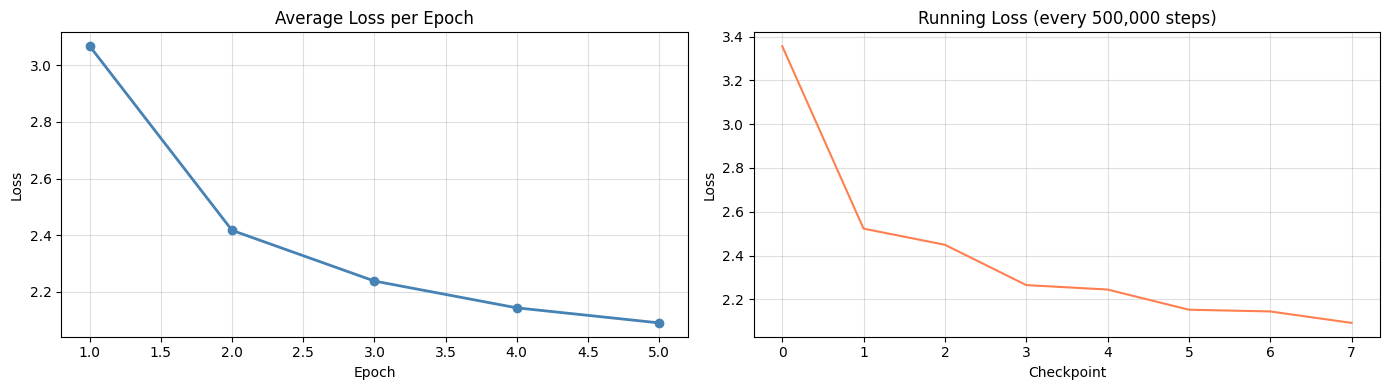

Loss curves saved.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Per-epoch loss
axes[0].plot(range(1, NUM_EPOCHS + 1), epoch_losses, marker='o', color='steelblue', linewidth=2)
axes[0].set_title('Average Loss per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True, alpha=0.4)

# Intra-training loss
if running_losses:
    axes[1].plot(running_losses, color='coral', linewidth=1.5)
    axes[1].set_title(f'Running Loss (every {LOG_INTERVAL:,} steps)')
    axes[1].set_xlabel('Checkpoint')
    axes[1].set_ylabel('Loss')
    axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('word2vec_loss_curves.png', dpi=150)
plt.show()
print('Loss curves saved.')

## 10. Saving Embeddings

In [10]:
# Save embeddings as NumPy array
embeddings = model.get_all_embeddings()          # shape: (VOCAB_SIZE, EMBED_DIM)
np.save('word_embeddings.npy', embeddings)

# Save vocabulary dictionaries for Part 2
with open('vocab.pkl', 'wb') as f:
    pickle.dump({'word2idx': word2idx, 'idx2word': idx2word}, f)

print(f'Embeddings saved  : word_embeddings.npy  {embeddings.shape}')
print(f'Vocabulary saved  : vocab.pkl')

Embeddings saved  : word_embeddings.npy  (13836, 100)
Vocabulary saved  : vocab.pkl


## 11. Word Analogy Function

Given three words *A*, *B*, *A\** — find *B\** such that:
$$\mathbf{v}_{B^*} \approx \mathbf{v}_B - \mathbf{v}_A + \mathbf{v}_{A^*}$$

In [11]:
def cosine_similarity(a: np.ndarray, b: np.ndarray) -> float:
    """Cosine similarity between two vectors."""
    denom = (np.linalg.norm(a) * np.linalg.norm(b))
    if denom == 0:
        return 0.0
    return float(np.dot(a, b) / denom)


def word_analogy(word_A: str, word_B: str, word_A_star: str,
                 embeddings: np.ndarray, word2idx: dict, idx2word: dict,
                 top_k: int = 5):
    """
    Solves analogy: A is to B as A* is to B*.
    i.e.  v(B*) ≈ v(B) - v(A) + v(A*)

    Parameters
    ----------
    word_A, word_B, word_A_star : query words
    embeddings                  : (VOCAB_SIZE, EMBED_DIM) matrix
    word2idx / idx2word         : vocabulary mappings
    top_k                       : number of candidates to return

    Returns
    -------
    List of (word, similarity_score) tuples.
    """
    for w in [word_A, word_B, word_A_star]:
        if w not in word2idx:
            print(f"  ⚠  '{w}' not in vocabulary.")
            return []

    v_A      = embeddings[word2idx[word_A]]
    v_B      = embeddings[word2idx[word_B]]
    v_A_star = embeddings[word2idx[word_A_star]]

    # Target vector
    target = v_B - v_A + v_A_star

    # Exclude the three query words from candidates
    exclude = {word2idx[word_A], word2idx[word_B], word2idx[word_A_star]}

    # Vectorised cosine similarity over the whole vocabulary
    norms     = np.linalg.norm(embeddings, axis=1, keepdims=True) + 1e-10
    normed    = embeddings / norms
    target_n  = target / (np.linalg.norm(target) + 1e-10)
    sims      = normed @ target_n                            # (VOCAB_SIZE,)

    # Zero out excluded indices
    for idx in exclude:
        sims[idx] = -np.inf

    top_indices = np.argsort(sims)[::-1][:top_k]
    results     = [(idx2word[i], float(sims[i])) for i in top_indices]
    return results


print('word_analogy function defined.')

word_analogy function defined.


### 11.1 Analogy Demo

In [12]:
def run_analogy(A, B, A_star):
    print(f'\n  Query : "{A}" is to "{B}" as "{A_star}" is to ?')
    results = word_analogy(A, B, A_star, embeddings, word2idx, idx2word, top_k=5)
    if results:
        print(f'  Top predictions:')
        for rank, (word, score) in enumerate(results, 1):
            print(f'    {rank}. {word:<20s}  sim = {score:.4f}')

# Example analogies on CoNLL-style news corpus
run_analogy('france',  'paris',   'germany')
run_analogy('january', 'feb',     'march')    # month abbreviations
run_analogy('he',      'his',     'she')


  Query : "france" is to "paris" as "germany" is to ?
  Top predictions:
    1. warsaw                sim = 0.8017
    2. johannesburg          sim = 0.7598
    3. bucharest             sim = 0.7418
    4. york                  sim = 0.7350
    5. wellington            sim = 0.7338

  Query : "january" is to "feb" as "march" is to ?
  Top predictions:
    1. gujral                sim = 0.6584
    2. brokers               sim = 0.6405
    3. 6000                  sim = 0.6383
    4. underwood             sim = 0.6366
    5. nv                    sim = 0.6363

  Query : "he" is to "his" as "she" is to ?
  Top predictions:
    1. her                   sim = 0.6925
    2. their                 sim = 0.6334
    3. my                    sim = 0.5523
    4. another               sim = 0.5257
    5. home                  sim = 0.5202


## 12. Nearest Neighbour Sanity Check

In [13]:
def most_similar(word: str, embeddings: np.ndarray, word2idx: dict,
                 idx2word: dict, top_k: int = 10):
    """Return the top_k most cosine-similar words."""
    if word not in word2idx:
        print(f"'{word}' not in vocabulary.")
        return []
    idx  = word2idx[word]
    vec  = embeddings[idx]
    norms = np.linalg.norm(embeddings, axis=1, keepdims=True) + 1e-10
    normed = embeddings / norms
    vec_n  = vec / (np.linalg.norm(vec) + 1e-10)
    sims   = normed @ vec_n
    sims[idx] = -np.inf
    top    = np.argsort(sims)[::-1][:top_k]
    return [(idx2word[i], float(sims[i])) for i in top]


for probe in ['london', 'president', 'soccer', 'killed']:
    if probe in word2idx:
        print(f"\nNearest to '{probe}':")
        for w, s in most_similar(probe, embeddings, word2idx, idx2word, top_k=5):
            print(f'  {w:<20s} {s:.4f}')


Nearest to 'london':
  bonn                 0.8443
  brussels             0.8062
  belgrade             0.8043
  jakarta              0.8005
  singapore            0.7949

Nearest to 'president':
  yasser               0.7665
  arafat               0.7342
  boris                0.7152
  palestinian          0.7147
  bill                 0.7074

Nearest to 'soccer':
  basketball           0.8543
  championship         0.8541
  cricket              0.8514
  premier              0.8436
  baseball             0.8318

Nearest to 'killed':
  arrested             0.9088
  seized               0.8644
  dead                 0.8614
  injured              0.8543
  wounded              0.8499


## Summary

| Component | Details |
|---|---|
| Model | Skip-Gram with Negative Sampling (SGNS) |
| Framework | Pure NumPy — no PyTorch autograd / nn.Module |
| Dataset | lhoestq/conll2003 (train + val + test) |
| Vocab size | see output above |
| Embed dim | 100 |
| Window size | 2 |
| Negatives (K) | 5 |
| Epochs | 5 |
| LR schedule | Linear decay 0.025 → 0.0001 |
| Outputs | `word_embeddings.npy`, `vocab.pkl` |